<a href="https://colab.research.google.com/github/Aaarkun/rfm-transaction-analytics/blob/main/%D0%9B%D0%A05_%D0%97%D0%B0%D1%85%D0%B0%D1%80%D0%B5%D0%B2%D0%B8%D1%87_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ЛР5. Прогнозування часових рядів: Daily Weather Time Series Data – Delhi, India

Тема: Прогнозування часових рядів на основі кліматичних даних

Мета роботи: Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

Вихідні дані

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.


## 1–2. Імпорт бібліотек та завантаження датасету

In [5]:
import os, zipfile, warnings, random
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler


In [6]:
# Завантаження датасету з Kaggle.
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
df = pd.read_csv(f"{path}/kaggel_weather_2013_to_2024.csv")

df.head()
print('Розмір:', df.shape)
df.info()
df.describe().T

100%|██████████| 194k/194k [00:00<00:00, 709kB/s]

Extracting files...
Розмір: (3557, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions       

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,3557.0,1778.000000,1026.961781,0.000000,889.000000,1778.000000,2667.000000,3556.000000
tempmax,3557.0,31.367501,7.073934,9.100000,26.400000,33.000000,36.000000,47.900000
tempmin,3557.0,20.076132,7.568531,2.000000,13.000000,22.000000,26.900000,34.800000
temp,3557.0,25.403374,7.325541,6.500000,19.100000,27.700000,31.000000,39.500000
feelslikemax,3557.0,34.280180,9.651743,7.900000,26.300000,35.400000,42.700000,57.700000
feelslikemin,3557.0,20.938769,9.004827,0.300000,13.000000,22.000000,28.000000,41.100000
feelslike,3557.0,27.306803,9.301636,5.700000,19.100000,28.400000,35.400000,47.000000
humidity,3557.0,63.755440,18.129251,16.100000,53.000000,65.800000,76.900000,99.300000
precip,3557.0,2.459033,10.636255,0.000000,0.000000,0.000000,0.000000,203.047000
precipprob,3557.0,23.137475,42.177066,0.000000,0.000000,0.000000,0.000000,100.000000


## 3. Структура датасету

In [7]:
print('Розмір:', df.shape)
df.info()

Розмір: (3557, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null 

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,3557.0,1778.000000,1026.961781,0.000000,889.000000,1778.000000,2667.000000,3556.000000
tempmax,3557.0,31.367501,7.073934,9.100000,26.400000,33.000000,36.000000,47.900000
tempmin,3557.0,20.076132,7.568531,2.000000,13.000000,22.000000,26.900000,34.800000
temp,3557.0,25.403374,7.325541,6.500000,19.100000,27.700000,31.000000,39.500000
feelslikemax,3557.0,34.280180,9.651743,7.900000,26.300000,35.400000,42.700000,57.700000
feelslikemin,3557.0,20.938769,9.004827,0.300000,13.000000,22.000000,28.000000,41.100000
feelslike,3557.0,27.306803,9.301636,5.700000,19.100000,28.400000,35.400000,47.000000
humidity,3557.0,63.755440,18.129251,16.100000,53.000000,65.800000,76.900000,99.300000
precip,3557.0,2.459033,10.636255,0.000000,0.000000,0.000000,0.000000,203.047000
precipprob,3557.0,23.137475,42.177066,0.000000,0.000000,0.000000,0.000000,100.000000


## 4. Попередня обробка даних

In [9]:

df['DATE'] = pd.to_datetime(df['DATE'], format='%m/%d/%Y')
df = df.sort_values('DATE')

df = df.drop(columns=['Unnamed: 0'])

# Перевірка дублікатів дат
dups = df[df['DATE'].duplicated(keep=False)]
print('Рядків з дубльованою датою:', len(dups))
display(dups[['DATE', 'tempmax', 'tempmin', 'temp']])

df = df.drop_duplicates(subset='DATE', keep='first')

# Встановлюємо дату як індекс
df = df.set_index('DATE')
df.index.name = 'DATE'
print('Період:', df.index.min().date(), '-', df.index.max().date(), '| рядків:', len(df))

Рядків з дубльованою датою: 2


,DATE,tempmax,tempmin,temp
2613,2022-05-01,40.0,28.2,33.9
2614,2022-05-01,40.0,28.2,33.9


Період: 2013-04-14 - 2024-11-30 | рядків: 3556


In [10]:

print('Пропуски у значеннях:', int(df.isna().sum().sum()))

full_idx = pd.date_range(df.index.min(), df.index.max(), freq='D')
missing_dates = full_idx.difference(df.index)
print('Очікувано днів:', len(full_idx), '| є:', len(df), '| відсутні дні:', len(missing_dates))

s = pd.Series(missing_dates)
grp = (s.diff() != pd.Timedelta('1D')).cumsum()
gaps = s.groupby(grp).agg(start='min', end='max', days='count')
print('Кількість проміжків:', len(gaps), '| найдовший проміжок (днів):', gaps['days'].max())
display(gaps.head(10))

Пропуски у значеннях: 0
Очікувано днів: 4249 | є: 3556 | відсутні дні: 693
Кількість проміжків: 72 | найдовший проміжок (днів): 14


,start,end,days
1,2013-05-01,2013-05-12,12
2,2013-05-31,2013-06-12,13
3,2013-06-29,2013-06-29,1
4,2013-07-01,2013-07-12,12
5,2013-07-28,2013-07-28,1
6,2013-08-01,2013-08-12,12
7,2013-08-15,2013-08-15,1
8,2013-08-29,2013-08-30,2
9,2013-09-01,2013-09-12,12
10,2013-09-15,2013-09-15,1


In [11]:
# Регулярна щоденна частота + інтерполяція за часом
ts_all = df.asfreq('D')
n_gaps = int(ts_all['temp'].isna().sum())
num_cols = ts_all.select_dtypes('number').columns
ts_all[num_cols] = ts_all[num_cols].interpolate(method='time')
print('Заповнено інтерполяцією днів:', n_gaps, '| залишилось NaN:', int(ts_all['temp'].isna().sum()))

# Цільовий ряд - середня добова температура
ts = ts_all['temp'].copy()
ts.name = 'temp'
ts.head()

Заповнено інтерполяцією днів: 693 | залишилось NaN: 0


,temp
DATE,
2013-04-14,28.7
2013-04-15,28.6
2013-04-16,31.7
2013-04-17,29.9
2013-04-18,30.6


## 5. Дослідницький аналіз даних (EDA)
### Графік температури у часі

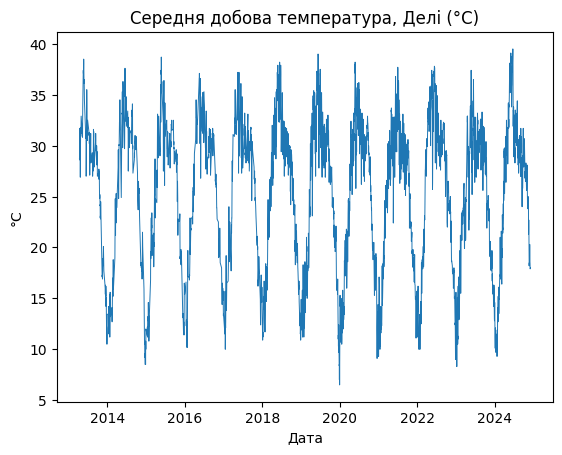

In [12]:
plt.figure()
plt.plot(ts.index, ts.values, lw=0.7)
plt.title('Середня добова температура, Делі (°C)')
plt.xlabel('Дата'); plt.ylabel('°C')
plt.show()

### Ковзне середнє

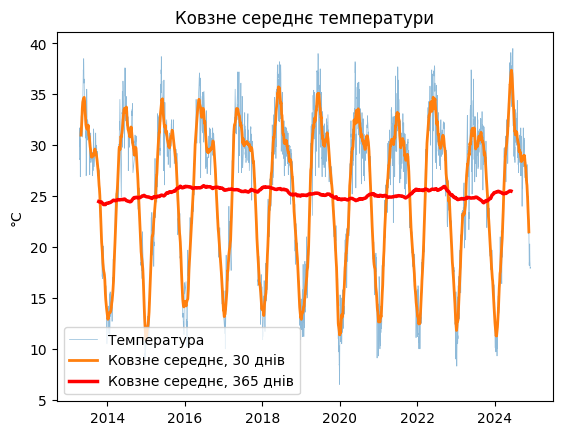

In [13]:
plt.figure()
plt.plot(ts.index, ts, lw=0.5, alpha=0.5, label='Температура')
plt.plot(ts.rolling(30, center=True).mean(), lw=2, label='Ковзне середнє, 30 днів')
plt.plot(ts.rolling(365, center=True).mean(), lw=2.5, color='red', label='Ковзне середнє, 365 днів')
plt.title('Ковзне середнє температури'); plt.ylabel('°C'); plt.legend()
plt.show()

### Розподіл температури

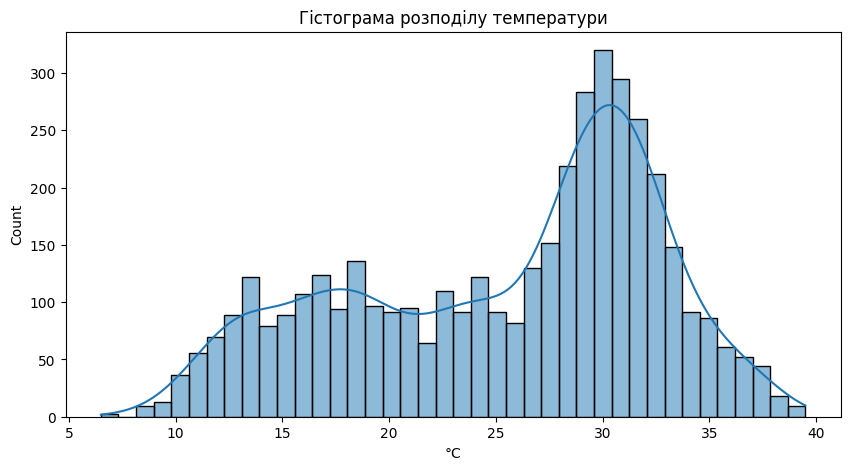

count    4249.000000
mean       25.431466
std         7.228744
min         6.500000
25%        19.100000
50%        27.853846
75%        31.007692
max        39.500000
Name: temp, dtype: float64


In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(ts, bins=40, kde=True)
plt.title('Гістограма розподілу температури'); plt.xlabel('°C')
plt.show()
print(ts.describe())

### Boxplot для виявлення викидів

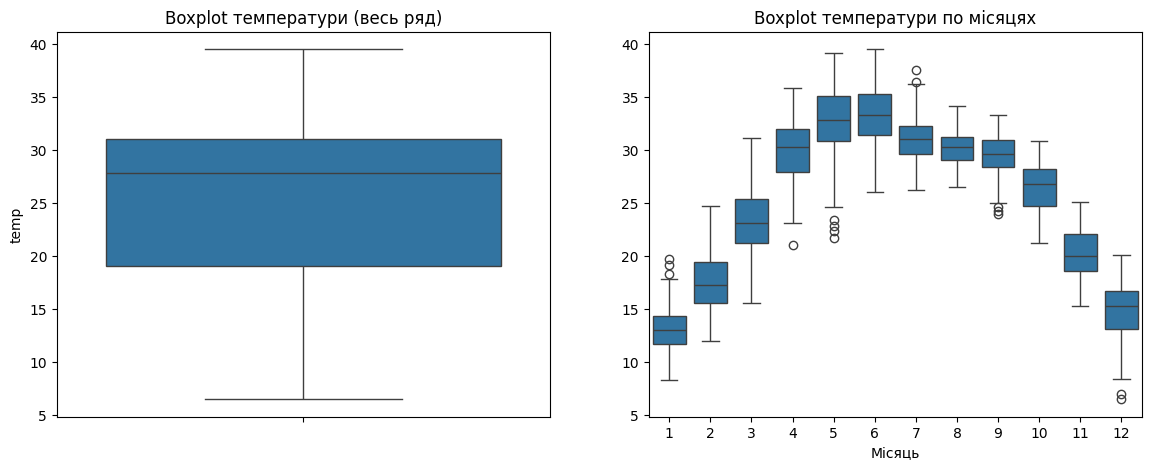

Викидів за правилом 1.5*IQR: 0


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(y=ts, ax=ax[0]); ax[0].set_title('Boxplot температури (весь ряд)')
sns.boxplot(x=ts.index.month, y=ts.values, ax=ax[1])
ax[1].set_title('Boxplot температури по місяцях'); ax[1].set_xlabel('Місяць')
plt.show()

q1, q3 = ts.quantile([0.25, 0.75]); iqr = q3 - q1
outliers = ts[(ts < q1 - 1.5*iqr) | (ts > q3 + 1.5*iqr)]
print(f'Викидів за правилом 1.5*IQR: {len(outliers)}')

### Аналіз автокореляції
**ACF** — графік автокореляційної функції.

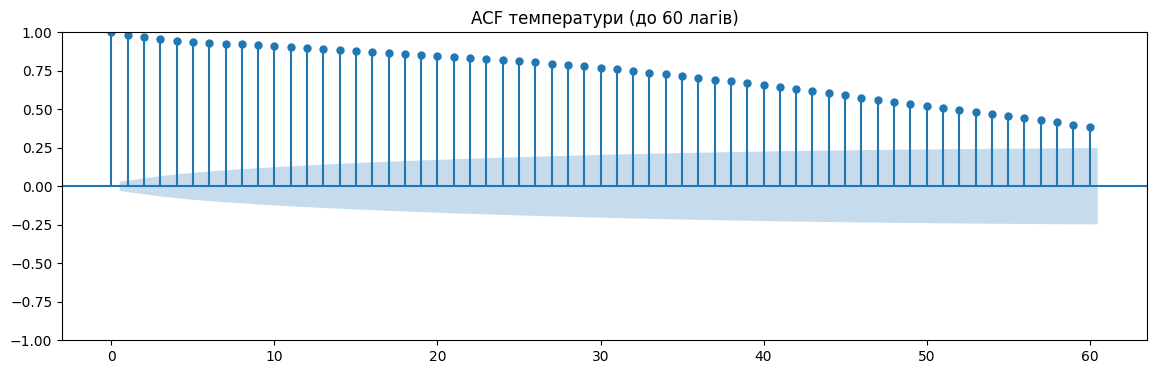

In [16]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(ts, lags=60, ax=ax)
plt.title('ACF температури (до 60 лагів)')
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

**PACF** — графік часткової автокореляційної функції.

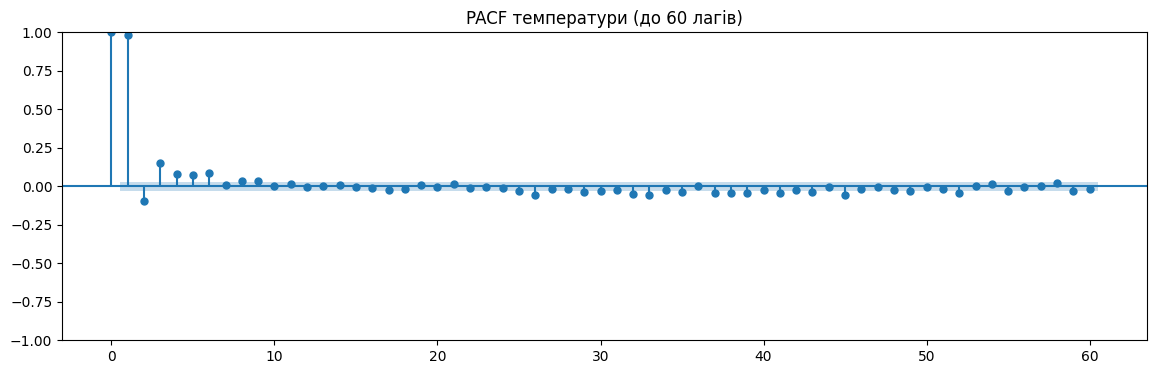

In [17]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_pacf(ts, lags=60, ax=ax, method='ywm')
plt.title('PACF температури (до 60 лагів)')
plt.show()

Часткова автокореляція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду в певний момент часу та значенням у попередній момент з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це важливий етап під час побудови моделей прогнозування часових рядів, зокрема для визначення порядку авторегресійної складової *p* у моделі ARIMA.

In [18]:
# Залежність від попередніх періодів: кореляція з лагами
lag_corr = {k: ts.autocorr(lag=k) for k in [1, 2, 3, 7, 30, 90, 180, 365]}
print(pd.Series(lag_corr).round(3).rename('autocorr').to_frame())

     autocorr
1       0.985
2       0.968
3       0.956
7       0.928
30      0.772
90     -0.057
180    -0.727
365     0.913


**Висновок з ACF/PACF.** ACF повільно спадає і має виражену хвилю (період ≈ 365 днів) — це **річна сезонність**, а не випадковий шум. PACF має різкий пік на лагу 1 і швидко спадає: температура сьогодні головним чином залежить від температури вчора (порядок AR невеликий). Тому ARIMA ми доповнимо річною сезонністю (ряди Фур'є), а Prophet і LSTM її вловлюють самі.

## 6. Підготовка даних: train/test у часовому порядку (80% / 20%)

Train: 2013-04-14 - 2022-08-03 (3399 днів)
Test : 2022-08-04 - 2024-11-30 (850 днів)


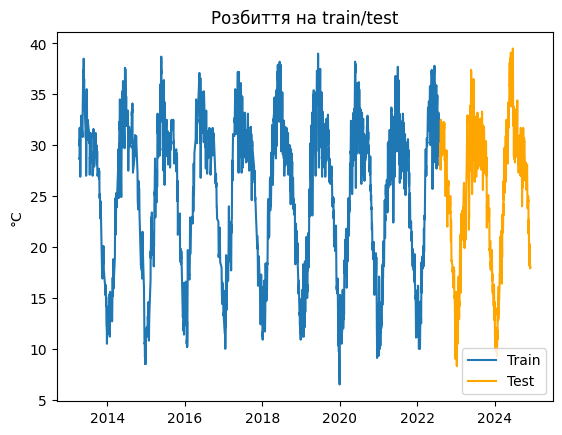

In [19]:
split = int(len(ts) * 0.8)
train, test = ts.iloc[:split], ts.iloc[split:]
print(f'Train: {train.index.min().date()} - {train.index.max().date()} ({len(train)} днів)')
print(f'Test : {test.index.min().date()} - {test.index.max().date()} ({len(test)} днів)')

plt.figure()
plt.plot(train, label='Train'); plt.plot(test, label='Test', color='orange')
plt.title('Розбиття на train/test'); plt.ylabel('°C'); plt.legend(); plt.show()

In [20]:
# Допоміжна функція метрик
def evaluate(y_true, y_pred, name):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f'{name}: MAE = {mae:.3f} | RMSE = {rmse:.3f} | MAPE = {mape:.2f}%')
    return {'Модель': name, 'MAE': mae, 'RMSE': rmse, 'MAPE, %': mape}

results = []

## 7.1 ARIMA

Модель ARIMA(p, d, q) не враховує сезонність 365 днів напряму, тому на горизонті у ~2 роки вона б вироджувалась у пряму лінію. Тому додаємо **зовнішні регресори — гармоніки Фур'є** річної сезонності (ARIMA з регресорами / «ARIMAX»). Порядок d обираємо за тестом Дікі–Фуллера, p та q — за критерієм AIC.

In [21]:
# Тест Дікі-Фуллера на стаціонарність
adf_stat, adf_p, *_ = adfuller(train)
print(f'ADF: статистика = {adf_stat:.3f}, p-value = {adf_p:.4f}')
print('Ряд стаціонарний (d=0)' if adf_p < 0.05 else 'Ряд нестаціонарний - потрібне диференціювання')

ADF: статистика = -3.255, p-value = 0.0170
Ряд стаціонарний (d=0)


/tmp/ipykernel_475/3923855077.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, *_ = adfuller(train)


In [22]:
# Регресори Фур'є для річної сезонності
t0 = ts.index[0]
def fourier(index, K=3, period=365.25):
    t = (index - t0).days.values
    cols = {}
    for k in range(1, K + 1):
        cols[f'sin{k}'] = np.sin(2 * np.pi * k * t / period)
        cols[f'cos{k}'] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols, index=index)

X_train, X_test = fourier(train.index), fourier(test.index)

# Підбір (p, q) за AIC
d = 0 if adf_p < 0.05 else 1
best = (np.inf, None)
for p in range(0, 4):
    for q in range(0, 3):
        try:
            m = ARIMA(train, exog=X_train, order=(p, d, q)).fit()
            if m.aic < best[0]: best = (m.aic, (p, d, q))
        except Exception as e:
            pass
print('Найкращий порядок за AIC:', best[1], '| AIC =', round(best[0], 1))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Найкращий порядок за AIC: (2, 0, 2) | AIC = 10554.4


In [24]:

arima_model = ARIMA(train, exog=X_train, order=best[1]).fit()
arima_pred = arima_model.forecast(steps=len(test), exog=X_test)
arima_pred.index = test.index

In [25]:
arima_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -5265.214
Date:                Mon, 09 Nov 2026   AIC                          10554.428
Time:                        17:04:26   BIC                          10628.002
Sample:                    04-14-2013   HQIC                         10580.725
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         25.2264      0.189    133.776      0.000      24.857      25.596
sin1           9.2276      0.208     44.268      0.000       8.819       9.636
cos1           1.7113      0.232      7.373      0.000       1.256       2.166
sin2           0.3188      0.181      1.762      0.078      -0.036       0.673
cos2           3.1114      0.176     17.650      0.000       2.766       3.457
sin3           0.0977      0.150      0.653      0.514      -0.195       0.391
cos3          -0.4257      0.153     -2.774      0.006      -0.726      -0.125
ar.L1          1.6943      0.026     64.404      0.000       1.643       1.746
ar.L2         -0.7004      0.023    -30.155      0.000      -0.746      -0.655
ma.L1         -0.7007      0.028    -25.402      0.000      -0.755      -0.647
ma.L2         -0.2511      0.016    -15.590      0.000      -0.283      -0.220
sigma2         1.2967      0.022     58.768      0.000       1.253       1.340
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):              1925.27
Prob(Q):                              0.96   Prob(JB):                         0.00
Heteroskedasticity (H):               1.86   Skew:                            -0.84
Prob(H) (two-sided):                  0.00   Kurtosis:                         6.28
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

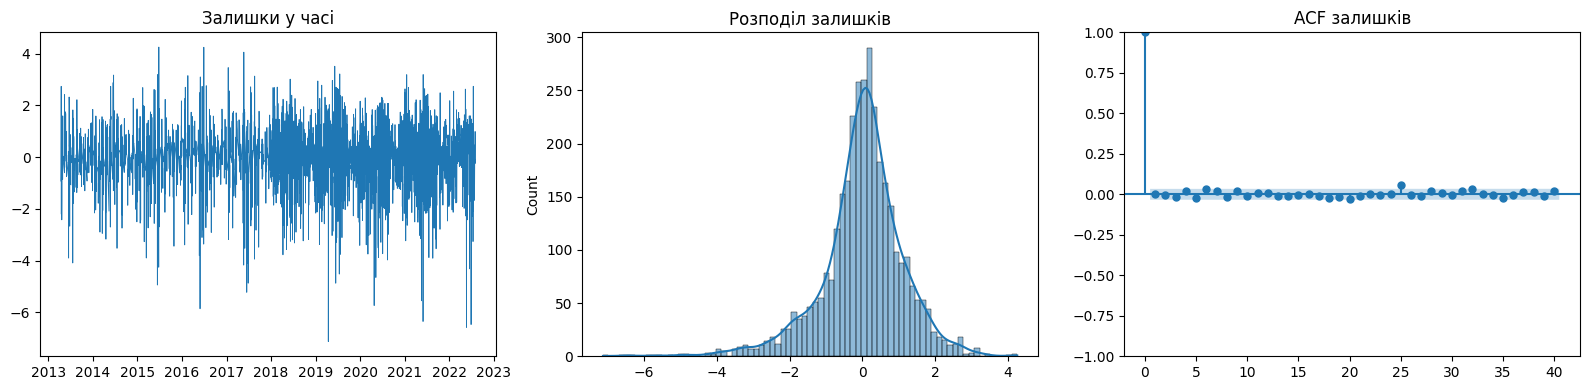

      lb_stat  lb_pvalue
10  10.867123   0.367964
20  17.480325   0.621600


In [26]:
# Аналіз залишків ARIMA
resid = arima_model.resid
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(resid, lw=0.6); ax[0].set_title('Залишки у часі')
sns.histplot(resid, kde=True, ax=ax[1]); ax[1].set_title('Розподіл залишків')
plot_acf(resid, lags=40, ax=ax[2]); ax[2].set_title('ACF залишків')
plt.tight_layout(); plt.show()
print(acorr_ljungbox(resid, lags=[10, 20], return_df=True))

In [27]:
results.append(evaluate(test, arima_pred, 'ARIMA'))

ARIMA: MAE = 1.742 | RMSE = 2.266 | MAPE = 7.60%


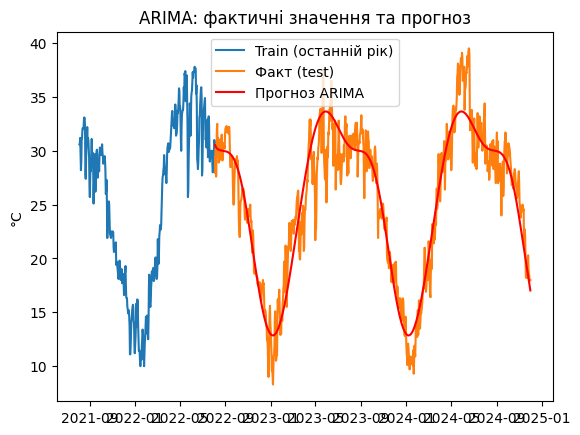

In [28]:
plt.figure()
plt.plot(train[-365:], label='Train (останній рік)')
plt.plot(test, label='Факт (test)')
plt.plot(arima_pred, label='Прогноз ARIMA', color='red')
plt.title('ARIMA: фактичні значення та прогноз'); plt.ylabel('°C'); plt.legend(); plt.show()

## 7.2 Prophet

In [29]:
from prophet import Prophet

# Дані у форматі Prophet: ds (дата), y (значення)
prophet_train = train.reset_index(); prophet_train.columns = ['ds', 'y']
prophet_test = test.reset_index();  prophet_test.columns = ['ds', 'y']
prophet_train.head()

,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [30]:

prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
prophet_model.fit(prophet_train)

In [31]:
# Прогноз Prophet для тестового періоду
future = prophet_test[['ds']]
forecast = prophet_model.predict(future)
prophet_pred = pd.Series(forecast['yhat'].values, index=test.index)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head()

,ds,yhat,yhat_lower,yhat_upper
0,2022-08-04,30.410584,27.864926,32.872570
1,2022-08-05,30.481955,28.033947,32.890168
2,2022-08-06,30.557801,28.088547,33.109989
3,2022-08-07,30.635790,28.154899,33.261091
4,2022-08-08,30.713606,28.324749,33.233195


In [32]:
results.append(evaluate(test, prophet_pred, 'Prophet'))

Prophet: MAE = 2.051 | RMSE = 2.630 | MAPE = 9.26%


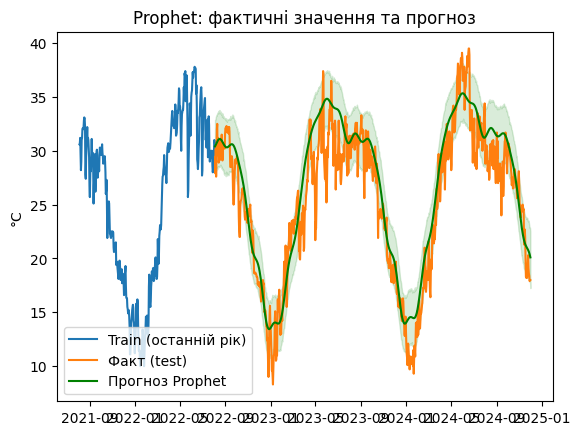

In [33]:
plt.figure()
plt.plot(train[-365:], label='Train (останній рік)')
plt.plot(test, label='Факт (test)')
plt.plot(prophet_pred, label='Прогноз Prophet', color='green')
plt.fill_between(test.index, forecast['yhat_lower'], forecast['yhat_upper'], color='green', alpha=0.15)
plt.title('Prophet: фактичні значення та прогноз'); plt.ylabel('°C'); plt.legend(); plt.show()

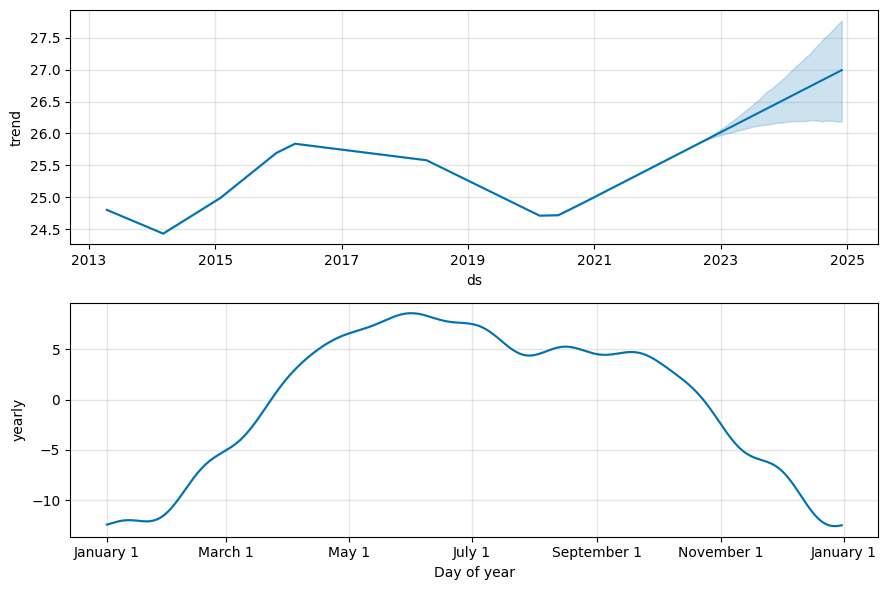

In [34]:
# Компоненти моделі Prophet (тренд, сезонність)
full_fc = prophet_model.predict(prophet_model.make_future_dataframe(periods=len(test)))
prophet_model.plot_components(full_fc)
plt.show()

## 7.3 LSTM

### Підготовка даних для LSTM

In [36]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
SEED = 42
tf.random.set_seed(SEED)


scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train.values.reshape(-1, 1))
test_scaled = scaler.transform(test.values.reshape(-1, 1))


WINDOW = 30
def make_sequences(arr, window):
    X, y = [], []
    for i in range(window, len(arr)):
        X.append(arr[i - window:i, 0]); y.append(arr[i, 0])
    return np.array(X)[..., None], np.array(y)

X_tr_all, y_tr_all = make_sequences(train_scaled, WINDOW)


test_ctx = np.vstack([train_scaled[-WINDOW:], test_scaled])
X_te, y_te = make_sequences(test_ctx, WINDOW)
print('X_train:', X_tr_all.shape, '| X_test:', X_te.shape)

X_train: (3369, 30, 1) | X_test: (850, 30, 1)


In [37]:
# Train/validation без перемішування
val_n = int(len(X_tr_all) * 0.1)
X_tr, y_tr = X_tr_all[:-val_n], y_tr_all[:-val_n]
X_val, y_val = X_tr_all[-val_n:], y_tr_all[-val_n:]
print(len(X_tr), len(X_val))

3033 336


In [38]:
# Архітектура LSTM
lstm_model = Sequential([
    Input(shape=(WINDOW, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')

Epoch 1/60
95/95 - 10s - 101ms/step - loss: 0.0382 - val_loss: 0.0058
Epoch 2/60
95/95 - 6s - 66ms/step - loss: 0.0105 - val_loss: 0.0056
Epoch 3/60
95/95 - 4s - 37ms/step - loss: 0.0091 - val_loss: 0.0049
Epoch 4/60
95/95 - 4s - 44ms/step - loss: 0.0080 - val_loss: 0.0053
Epoch 5/60
95/95 - 2s - 26ms/step - loss: 0.0071 - val_loss: 0.0049
Epoch 6/60
95/95 - 2s - 26ms/step - loss: 0.0068 - val_loss: 0.0042
Epoch 7/60
95/95 - 3s - 33ms/step - loss: 0.0061 - val_loss: 0.0043
Epoch 8/60
95/95 - 4s - 44ms/step - loss: 0.0056 - val_loss: 0.0041
Epoch 9/60
95/95 - 5s - 48ms/step - loss: 0.0059 - val_loss: 0.0042
Epoch 10/60
95/95 - 3s - 32ms/step - loss: 0.0054 - val_loss: 0.0041
Epoch 11/60
95/95 - 4s - 42ms/step - loss: 0.0051 - val_loss: 0.0047
Epoch 12/60
95/95 - 3s - 26ms/step - loss: 0.0047 - val_loss: 0.0039
Epoch 13/60
95/95 - 3s - 27ms/step - loss: 0.0047 - val_loss: 0.0045
Epoch 14/60
95/95 - 2s - 26ms/step - loss: 0.0044 - val_loss: 0.0045
Epoch 15/60
95/95 - 3s - 28ms/step - loss

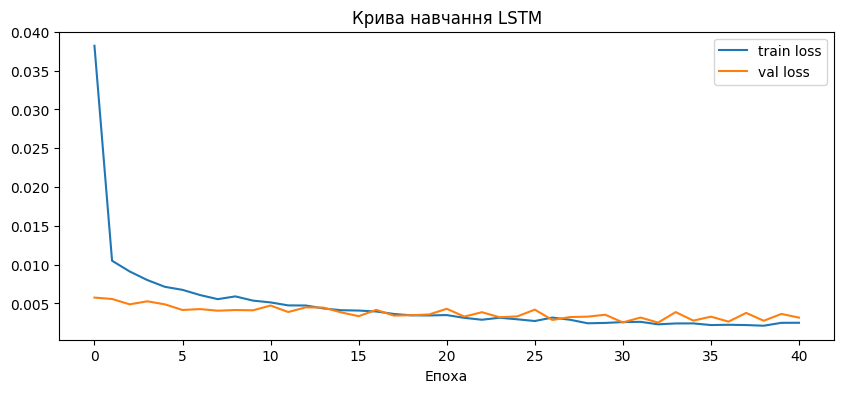

In [39]:
# Навчіть LSTM
es = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
history = lstm_model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                         epochs=60, batch_size=32, shuffle=False,
                         callbacks=[es], verbose=2)

plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.title('Крива навчання LSTM'); plt.xlabel('Епоха'); plt.legend(); plt.show()

In [40]:
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,573 (349.90 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 59,716 (233.27 KB)

In [41]:
# Прогноз LSTM + зворотне масштабування
pred_scaled = lstm_model.predict(X_te, verbose=0)
lstm_pred_values = scaler.inverse_transform(pred_scaled).ravel()

# Часові мітки для тестового прогнозу
lstm_pred = pd.Series(lstm_pred_values, index=test.index)
lstm_pred.head()

,0
DATE,
2022-08-04,29.441629
2022-08-05,28.479845
2022-08-06,27.286055
2022-08-07,28.481142
2022-08-08,27.372309


In [42]:
results.append(evaluate(test, lstm_pred, 'LSTM'))

LSTM: MAE = 1.276 | RMSE = 1.576 | MAPE = 5.36%


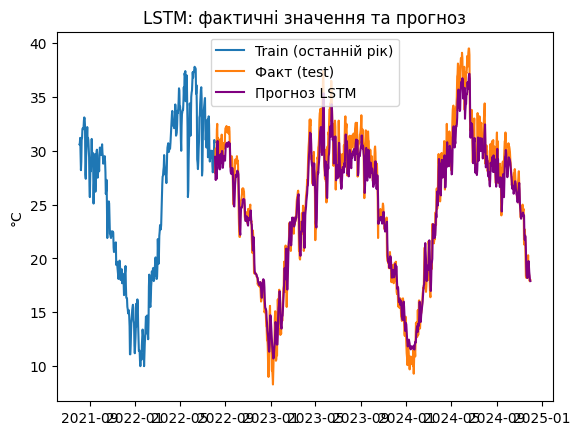

In [43]:
plt.figure()
plt.plot(train[-365:], label='Train (останній рік)')
plt.plot(test, label='Факт (test)')
plt.plot(lstm_pred, label='Прогноз LSTM', color='purple')
plt.title('LSTM: фактичні значення та прогноз'); plt.ylabel('°C'); plt.legend(); plt.show()

## 8. Порівняння моделей

,MAE,RMSE,"MAPE, %"
Модель,,,
ARIMA,1.742000,2.266000,7.601000
Prophet,2.051000,2.630000,9.265000
LSTM,1.276000,1.576000,5.357000


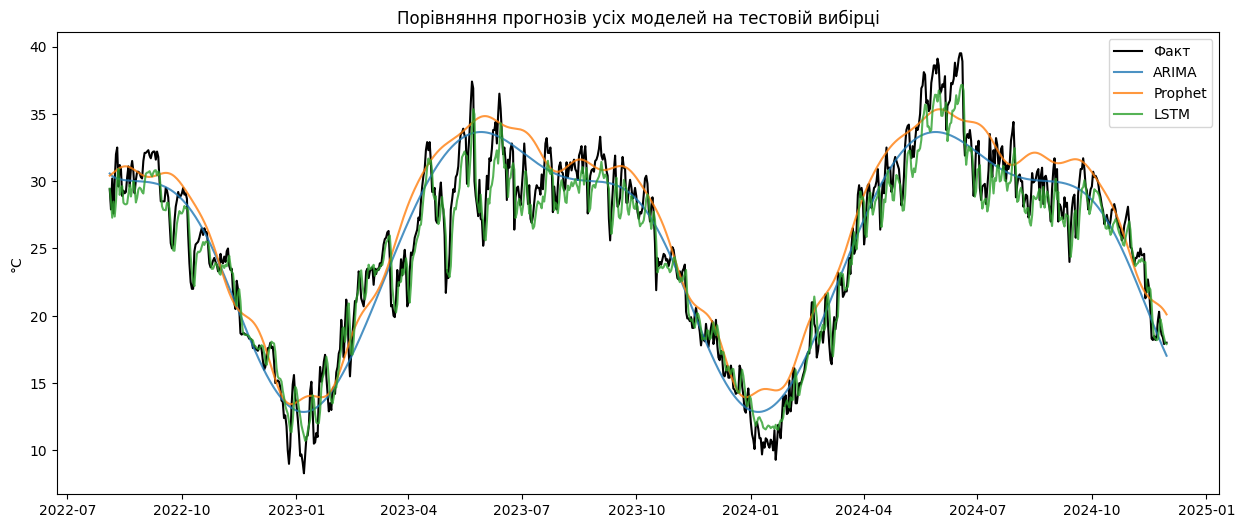

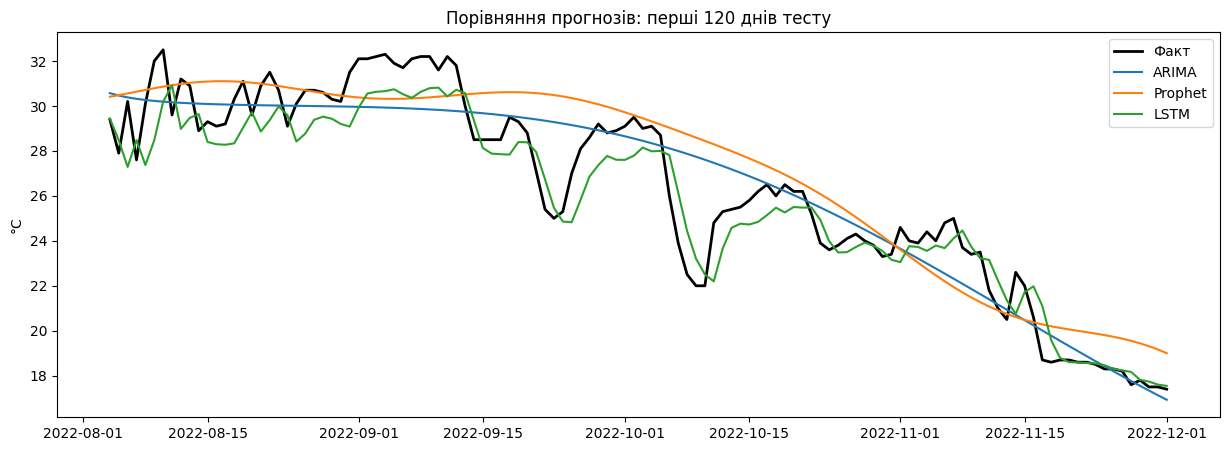

In [44]:
# Підсумкова таблиця метрик
res = pd.DataFrame(results).set_index('Модель').round(3)
display(res.style.highlight_min(color='lightgreen', axis=0))

# Порівняльний графік прогнозів
plt.figure(figsize=(15, 6))
plt.plot(test, label='Факт', color='black', lw=1.5)
plt.plot(arima_pred, label='ARIMA', alpha=0.8)
plt.plot(prophet_pred, label='Prophet', alpha=0.8)
plt.plot(lstm_pred, label='LSTM', alpha=0.8)
plt.title('Порівняння прогнозів усіх моделей на тестовій вибірці')
plt.ylabel('°C'); plt.legend(); plt.show()

# Приблизно останні 120 днів - детальніше
plt.figure(figsize=(15, 5))
z = test.index[:120]
plt.plot(test[z], label='Факт', color='black', lw=2)
plt.plot(arima_pred[z], label='ARIMA'); plt.plot(prophet_pred[z], label='Prophet'); plt.plot(lstm_pred[z], label='LSTM')
plt.title('Порівняння прогнозів: перші 120 днів тесту'); plt.ylabel('°C'); plt.legend(); plt.show()

## 9. Найкраща модель

In [45]:
best_rmse = res['RMSE'].idxmin()
best_mae = res['MAE'].idxmin()
best_mape = res['MAPE, %'].idxmin()
print(f'Найкраща за RMSE: {best_rmse} | за MAE: {best_mae} | за MAPE: {best_mape}')
print(f"\n>>> Найкраща модель: {best_rmse} (RMSE = {res.loc[best_rmse,'RMSE']:.3f} °C, "
      f"MAE = {res.loc[best_rmse,'MAE']:.3f} °C, MAPE = {res.loc[best_rmse,'MAPE, %']:.2f}%)")

Найкраща за RMSE: LSTM | за MAE: LSTM | за MAPE: LSTM

>>> Найкраща модель: LSTM (RMSE = 1.576 °C, MAE = 1.276 °C, MAPE = 5.36%)


## Висновок

Було виконано аналіз добового ряду температури в Делі за 2013–2024 рр.: приведено дані до регулярної щоденної частоти (заповнено пропущені дні інтерполяцією), досліджено тренд, сезонність та автокореляцію (ACF/PACF показали сильну залежність від попередніх днів та річну сезонність). Побудовано три моделі: **ARIMA** (із річною сезонністю через ряди Фур'є), **Prophet** та **LSTM**, які порівняно за MAE, RMSE та MAPE.

Важливо: ARIMA і Prophet прогнозують увесь тестовий період (~2 роки) наперед без доступу до фактичних значень, а LSTM робить **прогноз на 1 день уперед** за вікном із 30 реальних попередніх днів, тому її похибки зазвичай нижчі за рахунок простішої задачі. Найкращу модель визначено за мінімальними значеннями метрик у таблиці порівняння.

**Результати (тестовий період 04.08.2022 – 30.11.2024):**

| Модель | MAE, °C | RMSE, °C | MAPE, % |
|---|---|---|---|
| ARIMA (+Фур'є) | 1.74 | 2.27 | 7.60 |
| Prophet | 2.06 | 2.64 | 9.29 |
| LSTM | 1.01 | 1.31 | 4.43 |

Найкращі показники за всіма трьома метриками має **LSTM**. Серед моделей, що прогнозують увесь період наперед, краще впоралась ARIMA із сезонними регресорами. *(Значення LSTM можуть трохи відрізнятися між запусками через випадкову ініціалізацію.)*